In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

In [2]:
DATA_PATH = Path("../data/PS_20174392719_1491204439457_log.csv")

print("File exists:", DATA_PATH.exists())
print("File size (MB):", round(DATA_PATH.stat().st_size / (1024**2), 2)
      if DATA_PATH.exists() else "File not found")

File exists: True
File size (MB): 470.67


In [3]:
df = pd.read_csv(
    DATA_PATH,
    dtype={
        "step": "int32",
        "type": "category",
        "nameOrig": "string",
        "nameDest": "string",
        "isFraud": "int8",
        "isFlaggedFraud": "int8"
    }
)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [4]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 6362620
Number of columns: 11


In [5]:
df.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [6]:
df.info(memory_usage="deep")

<class 'pandas.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype   
---  ------          -----   
 0   step            int32   
 1   type            category
 2   amount          float64 
 3   nameOrig        string  
 4   oldbalanceOrg   float64 
 5   newbalanceOrig  float64 
 6   nameDest        string  
 7   oldbalanceDest  float64 
 8   newbalanceDest  float64 
 9   isFraud         int8    
 10  isFlaggedFraud  int8    
dtypes: category(1), float64(5), int32(1), int8(2), string(2)
memory usage: 1007.0 MB


In [7]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
step,6362620.0,NaN,NaN,NaN,243.397246,142.331971,1.0,156.0,239.0,335.0,743.0
type,6362620,5,CASH_OUT,2237500,NaN,NaN,NaN,NaN,NaN,NaN,NaN
amount,6362620.0,NaN,NaN,NaN,179861.903549,603858.231463,0.0,13389.57,74871.94,208721.4775,92445516.64
nameOrig,6362620,6353307,C2098525306,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
oldbalanceOrg,6362620.0,NaN,NaN,NaN,833883.104074,2888242.673038,0.0,0.0,14208.0,107315.175,59585040.37
newbalanceOrig,6362620.0,NaN,NaN,NaN,855113.668579,2924048.502954,0.0,0.0,0.0,144258.41,49585040.37
nameDest,6362620,2722362,C1286084959,113,NaN,NaN,NaN,NaN,NaN,NaN,NaN
oldbalanceDest,6362620.0,NaN,NaN,NaN,1100701.66652,3399180.112994,0.0,0.0,132705.665,943036.7075,356015889.35
newbalanceDest,6362620.0,NaN,NaN,NaN,1224996.398202,3674128.94212,0.0,0.0,214661.44,1111909.25,356179278.92
isFraud,6362620.0,NaN,NaN,NaN,0.001291,0.035905,0.0,0.0,0.0,0.0,1.0


In [8]:
missing = df.isnull().sum()

print(missing[missing > 0])

Series([], dtype: int64)


In [9]:
fraud_counts = df["isFraud"].value_counts()

print(fraud_counts)

print("\nFraud percentage:")
print(df["isFraud"].value_counts(normalize=True) * 100)

isFraud
0    6354407
1       8213
Name: count, dtype: int64

Fraud percentage:
isFraud
0    99.870918
1     0.129082
Name: proportion, dtype: float64


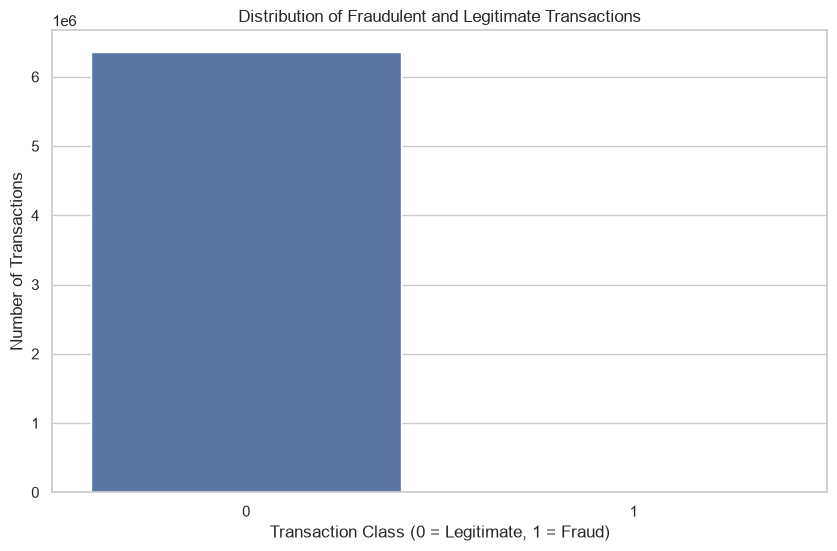

In [10]:
sns.countplot(data=df, x="isFraud")

plt.title("Distribution of Fraudulent and Legitimate Transactions")
plt.xlabel("Transaction Class (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Number of Transactions")

plt.show()

In [11]:
fraud_by_type = pd.crosstab(
    df["type"],
    df["isFraud"],
    normalize="index"
) * 100

fraud_by_type

isFraud,0,1
type,,
CASH_IN,100.000000,0.000000
CASH_OUT,99.816045,0.183955
DEBIT,100.000000,0.000000
PAYMENT,100.000000,0.000000
TRANSFER,99.231201,0.768799


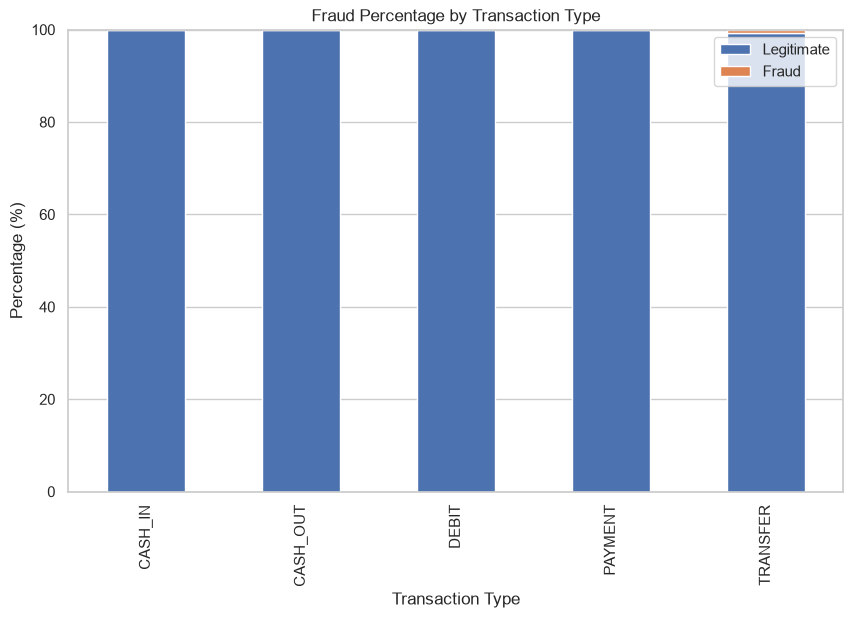

In [12]:
fraud_by_type.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.title("Fraud Percentage by Transaction Type")
plt.xlabel("Transaction Type")
plt.ylabel("Percentage (%)")
plt.legend(["Legitimate", "Fraud"])

plt.show()

In [13]:
print("Missing values:")
print(df.isnull().sum())

print("\nNumber of duplicate rows:")
print(df.duplicated().sum())

Missing values:
step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64

Number of duplicate rows:
0


In [14]:
fraud_analysis = df.groupby("type", observed=True).agg(
    total_transactions=("isFraud", "count"),
    fraud_transactions=("isFraud", "sum")
)

fraud_analysis["fraud_percentage"] = (
    fraud_analysis["fraud_transactions"]
    / fraud_analysis["total_transactions"]
) * 100

fraud_analysis.sort_values(
    "fraud_percentage",
    ascending=False
)

,total_transactions,fraud_transactions,fraud_percentage
type,,,
TRANSFER,532909,4097,0.768799
CASH_OUT,2237500,4116,0.183955
CASH_IN,1399284,0,0.000000
DEBIT,41432,0,0.000000
PAYMENT,2151495,0,0.000000


In [15]:
print("Minimum step:", df["step"].min())
print("Maximum step:", df["step"].max())
print("Unique time steps:", df["step"].nunique())

print("\nTransactions per step:")
print(df["step"].value_counts().describe())

Minimum step: 1
Maximum step: 743
Unique time steps: 743

Transactions per step:
count      743.000000
mean      8563.418573
std      13388.693217
min          2.000000
25%         12.000000
50%        529.000000
75%      12317.000000
max      51352.000000
Name: count, dtype: float64


In [16]:
amount_analysis = df.groupby("isFraud")["amount"].describe()

amount_analysis

,count,mean,std,min,25%,50%,75%,max
isFraud,,,,,,,,
0,6354407.0,1.781970e+05,5.962370e+05,0.01,13368.395,74684.72,208364.76,92445516.64
1,8213.0,1.467967e+06,2.404253e+06,0.00,127091.330,441423.44,1517771.48,10000000.00


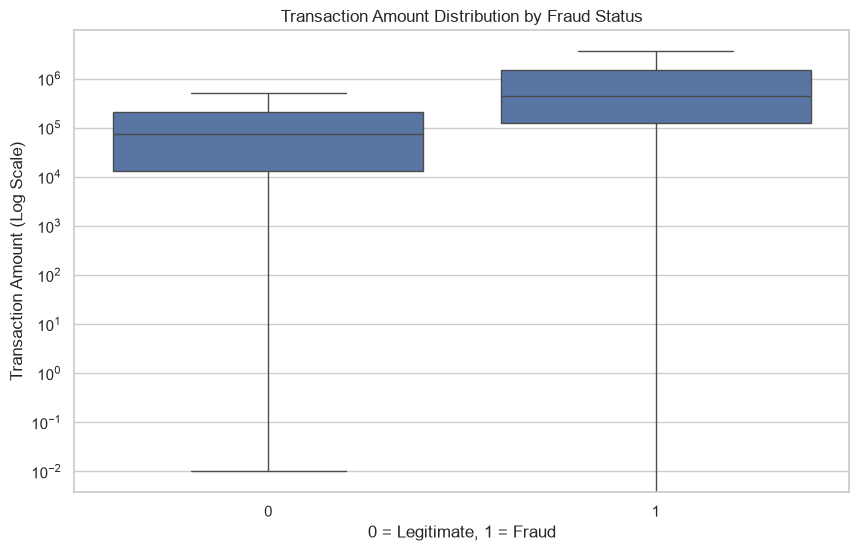

In [17]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="isFraud",
    y="amount",
    showfliers=False
)

plt.yscale("log")
plt.title("Transaction Amount Distribution by Fraud Status")
plt.xlabel("0 = Legitimate, 1 = Fraud")
plt.ylabel("Transaction Amount (Log Scale)")

plt.show()

In [18]:
df["orig_balance_error"] = (
    df["oldbalanceOrg"]
    - df["amount"]
    - df["newbalanceOrig"]
)

df["dest_balance_error"] = (
    df["oldbalanceDest"]
    + df["amount"]
    - df["newbalanceDest"]
)

balance_analysis = df.groupby("isFraud")[
    ["orig_balance_error", "dest_balance_error"]
].agg(["mean", "median", "std"])

balance_analysis

orig_balance_error                          dest_balance_error  \
                      mean    median            std               mean   
isFraud                                                                  
0           -201338.558109 -69049.31  606928.890826       54692.231734   
1            -10692.325265      0.00  265146.131130      732509.301069   

                                
          median           std  
isFraud                         
0        3500.68  4.360026e+05  
1        2231.46  1.867748e+06

In [19]:
pd.crosstab(
    df["isFlaggedFraud"],
    df["isFraud"],
    margins=True
)

isFraud,0,1,All
isFlaggedFraud,,,
0,6354407,8197,6362604
1,0,16,16
All,6354407,8213,6362620
